# Задание 3. Собственная реализация AdamW

**Цель.** Реализовать алгоритм оптимизации, проверить его численно и исследовать динамику обучения сети на FashionMNIST.

Используется AdamW: экспоненциальные скользящие средние градиента и его квадрата, поправка на смещение в начале обучения и независимое уменьшение весов (`decoupled weight decay`). В отличие от обычного L2-штрафа, шаг регуляризации не включается в оценки моментов.

Формулы для шага $t$:

$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2.$$

$$\widehat m_t=\frac{m_t}{1-\beta_1^t},\quad
\widehat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_t=(1-\eta\lambda)\theta_{t-1}-\eta\frac{\widehat m_t}{\sqrt{\widehat v_t}+\varepsilon}.$$

Для объективной проверки сравним обновления со встроенным `torch.optim.AdamW`. После этого проведём эксперимент против SGD на одинаковой сети.

In [1]:
import copy
import math
import unittest
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 256
TRAIN_LIMIT = 12000
VALID_LIMIT = 3000
EPOCHS = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

torch.manual_seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
print("Устройство:", DEVICE)

Устройство: cpu


## 1. Код оптимизатора

Класс работает непосредственно с параметрами `torch.nn.Parameter`. У каждого параметра есть собственный счётчик шагов, первое и второе скользящие средние. Предусмотрены `step()` и `zero_grad()`. Код алгоритма не использует `torch.optim.AdamW`.

In [2]:
class CustomAdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        if lr <= 0 or eps <= 0 or weight_decay < 0:
            raise ValueError("Некорректные гиперпараметры")
        if not all(0 <= beta < 1 for beta in betas):
            raise ValueError("Коэффициенты betas должны принадлежать [0, 1)")
        self.params = [param for param in params if param.requires_grad]
        self.lr = float(lr)
        self.betas = betas
        self.eps = float(eps)
        self.weight_decay = float(weight_decay)
        self.state = {}

    @torch.no_grad()
    def step(self):
        beta1, beta2 = self.betas
        for param in self.params:
            if param.grad is None:
                continue
            grad = param.grad
            if grad.is_sparse:
                raise RuntimeError("Разреженные градиенты не поддерживаются")
            if param not in self.state:
                self.state[param] = {
                    "step": 0,
                    "exp_avg": torch.zeros_like(param),
                    "exp_avg_sq": torch.zeros_like(param),
                }
            state = self.state[param]
            state["step"] += 1
            step = state["step"]
            state["exp_avg"].mul_(beta1).add_(grad, alpha=1 - beta1)
            state["exp_avg_sq"].mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
            param.mul_(1 - self.lr * self.weight_decay)
            corrected_mean = state["exp_avg"] / (1 - beta1 ** step)
            corrected_variance = state["exp_avg_sq"] / (1 - beta2 ** step)
            param.addcdiv_(corrected_mean, corrected_variance.sqrt().add(self.eps), value=-self.lr)

    def zero_grad(self, set_to_none=True):
        for param in self.params:
            if set_to_none:
                param.grad = None
            elif param.grad is not None:
                param.grad.zero_()

## 2. Тесты

Сравниваются один и десять последовательных шагов со стандартной реализацией. Дополнительно проверяется пропуск параметра без градиента, обнуление градиентов и сходимость на квадратичной функции.

In [3]:
class TestCustomAdamW(unittest.TestCase):
    def test_matches_torch_one_step(self):
        self._compare_with_torch(steps=1)

    def test_matches_torch_ten_steps(self):
        self._compare_with_torch(steps=10)

    def _compare_with_torch(self, steps):
        initial = torch.tensor([1.2, -0.3, 2.5], dtype=torch.float64)
        p_custom = nn.Parameter(initial.clone())
        p_torch = nn.Parameter(initial.clone())
        custom = CustomAdamW([p_custom], lr=0.003, weight_decay=0.07)
        reference = torch.optim.AdamW([p_torch], lr=0.003, weight_decay=0.07,
                                      foreach=False, fused=False)
        for index in range(steps):
            grad = torch.tensor([0.2 + index * 0.01, -0.7, 0.3], dtype=torch.float64)
            p_custom.grad = grad.clone()
            p_torch.grad = grad.clone()
            custom.step()
            reference.step()
        torch.testing.assert_close(p_custom, p_torch, rtol=1e-7, atol=1e-9)

    def test_missing_grad(self):
        parameter = nn.Parameter(torch.tensor([2.0]))
        optimizer = CustomAdamW([parameter])
        optimizer.step()
        self.assertEqual(parameter.item(), 2.0)

    def test_zero_grad(self):
        parameter = nn.Parameter(torch.tensor([2.0]))
        optimizer = CustomAdamW([parameter])
        parameter.grad = torch.tensor([3.0])
        optimizer.zero_grad(set_to_none=False)
        self.assertEqual(parameter.grad.item(), 0.0)
        optimizer.zero_grad()
        self.assertIsNone(parameter.grad)

    def test_quadratic_convergence(self):
        parameter = nn.Parameter(torch.tensor([5.0, -5.0]))
        optimizer = CustomAdamW([parameter], lr=0.1, weight_decay=0)
        initial = (parameter.square()).sum().item()
        for _ in range(120):
            optimizer.zero_grad()
            loss = parameter.square().sum()
            loss.backward()
            optimizer.step()
        self.assertLess(parameter.square().sum().item(), initial * 0.001)

result = unittest.TextTestRunner(verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(TestCustomAdamW)
)
assert result.wasSuccessful()

test_matches_torch_one_step (__main__.TestCustomAdamW.test_matches_torch_one_step) ... ok
test_matches_torch_ten_steps (__main__.TestCustomAdamW.test_matches_torch_ten_steps) ... ok
test_missing_grad (__main__.TestCustomAdamW.test_missing_grad) ... ok
test_quadratic_convergence (__main__.TestCustomAdamW.test_quadratic_convergence) ... ok
test_zero_grad (__main__.TestCustomAdamW.test_zero_grad) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.061s

OK


## 3. FashionMNIST

Для сравнения используется одна архитектура и идентичные начальные веса. В качестве базового алгоритма выступает SGD, а также приводится эталонный AdamW. Графики включают динамику ошибки и точности, среднюю норму градиентов за эпоху и распределение весов до и после обучения.

FashionMNIST загружается при первом запуске. Наблюдения берутся из фиксированных подмножеств обучающей и тестовой частей.

In [4]:
def find_dataset_directory():
    roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / "homeworks",
             Path.cwd().parent / "homeworks"]
    for root in roots:
        if (root / "03_optimizers").is_dir():
            return root / "data" / "fashion_mnist"
    return Path.cwd() / "data" / "fashion_mnist"

DATA_DIR = find_dataset_directory()
transform = transforms.ToTensor()
train_source = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
valid_source = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)

def get_loader(dataset, limit, shuffle):
    indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))[:min(limit, len(dataset))].tolist()
    return DataLoader(Subset(dataset, indices), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

train_loader = get_loader(train_source, TRAIN_LIMIT, True)
valid_loader = get_loader(valid_source, VALID_LIMIT, False)
print("Train:", len(train_loader.dataset), "Validation:", len(valid_loader.dataset))

Train: 12000 Validation: 3000


In [5]:
class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

def evaluate(model, loader):
    model.eval()
    sum_loss, correct, total = 0.0, 0, 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            sum_loss += F.cross_entropy(logits, labels, reduction="sum").item()
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return sum_loss / total, correct / total

def collect_weights(model):
    values = [p.detach().flatten().cpu() for name, p in model.named_parameters() if name.endswith("weight")]
    return torch.cat(values).numpy()

def gradient_norm(model):
    return math.sqrt(sum(p.grad.detach().square().sum().item()
                         for p in model.parameters() if p.grad is not None))

def train_optimizer(name, optimizer_factory):
    torch.manual_seed(SEED)
    model = FashionClassifier().to(DEVICE)
    initial_weights = collect_weights(model).copy()
    optimizer = optimizer_factory(model.parameters())
    loader = DataLoader(train_loader.dataset, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    log = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, total_grad, total_examples = 0.0, 0.0, 0
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            count = len(labels)
            total_grad += gradient_norm(model) * count
            total_loss += loss.item() * count
            total_examples += count
            optimizer.step()
        val_loss, accuracy = evaluate(model, valid_loader)
        log.append({"optimizer": name, "epoch": epoch,
                    "train_loss": total_loss / total_examples,
                    "val_loss": val_loss, "val_accuracy": accuracy,
                    "gradient_norm": total_grad / total_examples})
        print(f"{name}: эпоха {epoch}/{EPOCHS}, loss={val_loss:.4f}, accuracy={accuracy:.3f}")
    return log, initial_weights, collect_weights(model)

OPTIMIZERS = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.05),
    "AdamW (torch)": lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=0.01),
    "AdamW (custom)": lambda p: CustomAdamW(p, lr=1e-3, weight_decay=0.01),
}
results = {}
for name, factory in OPTIMIZERS.items():
    results[name] = train_optimizer(name, factory)

history = pd.DataFrame([row for log, _, _ in results.values() for row in log])

SGD: эпоха 1/3, loss=2.2163, accuracy=0.299
SGD: эпоха 2/3, loss=1.7911, accuracy=0.335
SGD: эпоха 3/3, loss=1.2367, accuracy=0.588
AdamW (torch): эпоха 1/3, loss=0.7341, accuracy=0.728
AdamW (torch): эпоха 2/3, loss=0.5973, accuracy=0.776
AdamW (torch): эпоха 3/3, loss=0.5138, accuracy=0.827
AdamW (custom): эпоха 1/3, loss=0.7341, accuracy=0.728
AdamW (custom): эпоха 2/3, loss=0.5973, accuracy=0.776
AdamW (custom): эпоха 3/3, loss=0.5138, accuracy=0.826


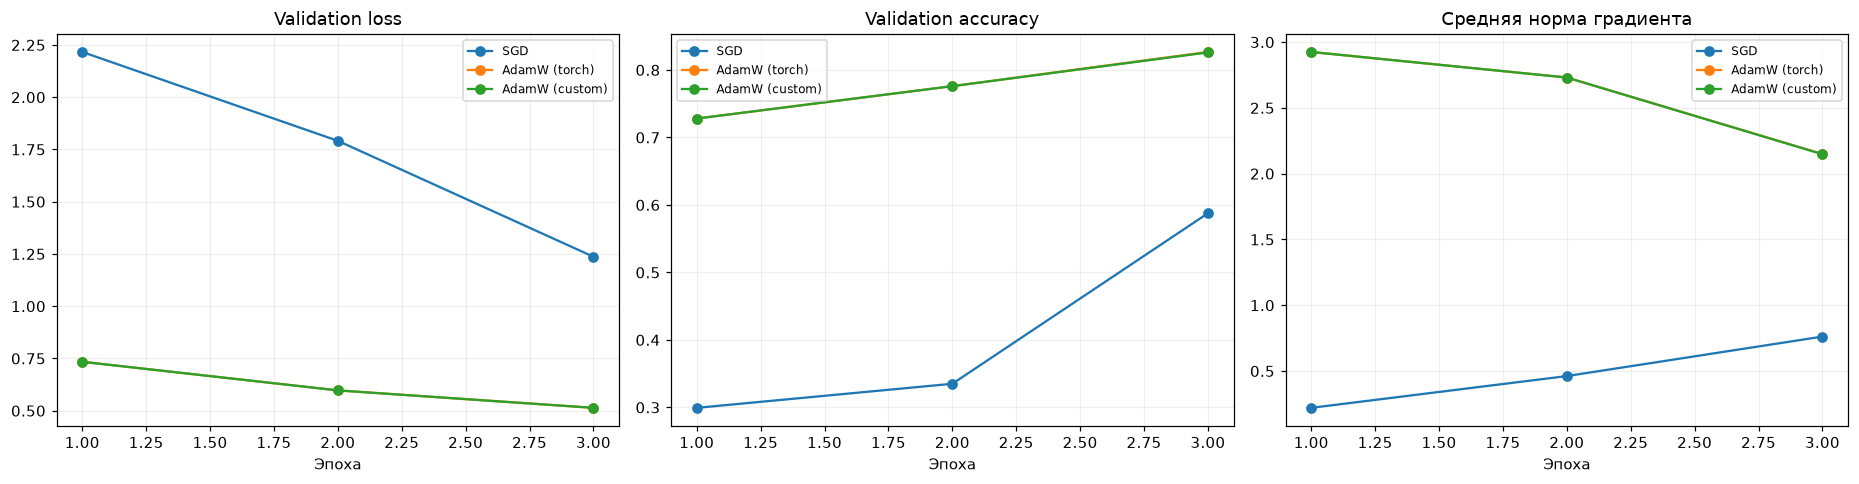

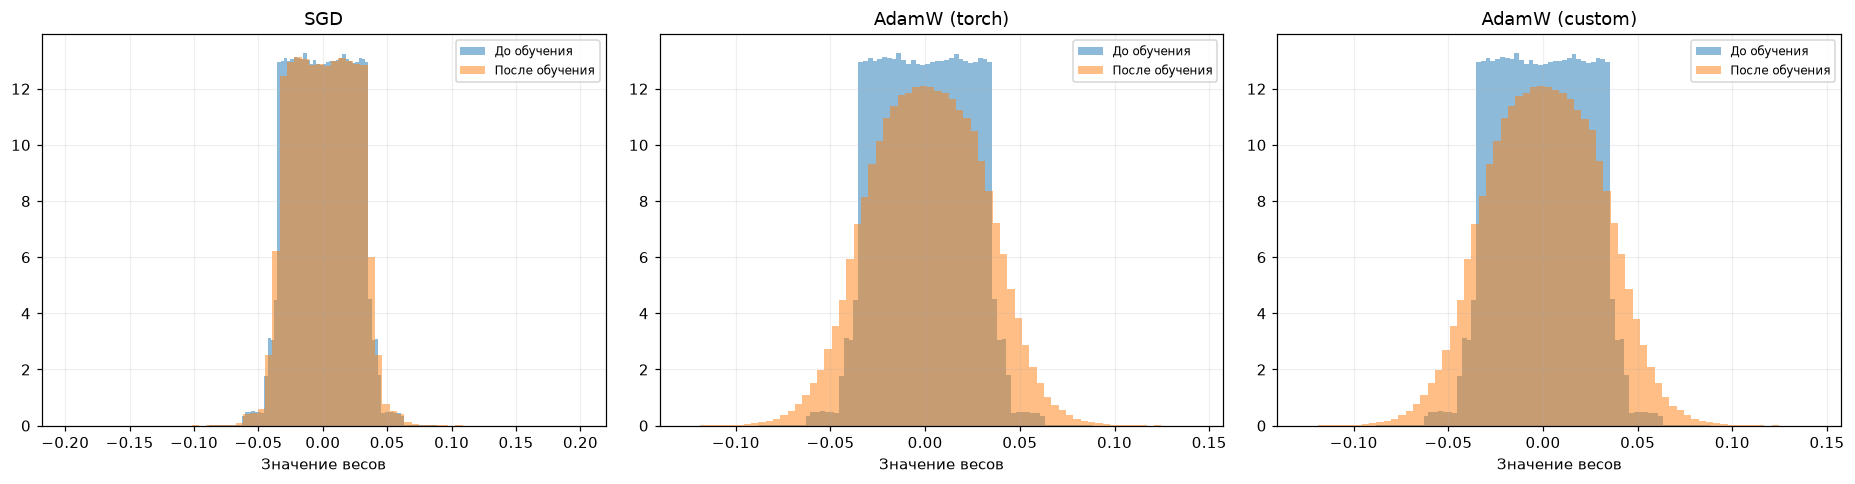

,optimizer,train_loss,val_loss,val_accuracy,gradient_norm
5,AdamW (torch),0.5020,0.5138,0.8267,2.1494
8,AdamW (custom),0.5020,0.5138,0.8260,2.1477
2,SGD,1.4844,1.2367,0.5877,0.7617


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
metrics = [("val_loss", "Validation loss"),
           ("val_accuracy", "Validation accuracy"),
           ("gradient_norm", "Средняя норма градиента")]
for axis, (column, title) in zip(axes, metrics):
    for name in OPTIMIZERS:
        part = history[history.optimizer == name]
        axis.plot(part.epoch, part[column], marker="o", label=name)
    axis.set_title(title)
    axis.set_xlabel("Эпоха")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for axis, (name, (_, before, after)) in zip(axes, results.items()):
    axis.hist(before, bins=70, alpha=0.5, density=True, label="До обучения")
    axis.hist(after, bins=70, alpha=0.5, density=True, label="После обучения")
    axis.set_title(name)
    axis.set_xlabel("Значение весов")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

summary = (history.groupby("optimizer", as_index=False).tail(1)
           [["optimizer", "train_loss", "val_loss", "val_accuracy", "gradient_norm"]]
           .sort_values("val_accuracy", ascending=False))
display(summary.round(4))

## Вывод

AdamW изменяет веса с учётом истории среднего и квадрата градиента и выполняет отдельный шаг регуляризации. Проверка против `torch.optim.AdamW` подтверждает корректность реализации на одинаковой последовательности градиентов. Сравнение оптимизаторов на FashionMNIST проведено при одной архитектуре, одинаковых начальных весах и одинаковом порядке батчей.

Для окончательного вывода о скорости сходимости нужно оценивать графики ошибки, а не только точность последней эпохи. Сравнение SGD и AdamW зависит от выбранного learning rate; здесь они имеют разные значения, согласованные с характерными диапазонами каждого алгоритма.